In [ ]:
from pathlib import Path
import os
PROJECT_DIR = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "app.py").is_file())
os.chdir(PROJECT_DIR)
Path("reports/figures").mkdir(parents=True, exist_ok=True)
Path("data/processed").mkdir(parents=True, exist_ok=True)


In [2]:
import pandas as pd
import numpy as np
import os
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

os.chdir(PROJECT_DIR)

# Buat folder penyimpanan model jika belum ada
os.makedirs("models", exist_ok=True)

# 1. Load Data
df_sibi = pd.read_csv("data/processed/sibi_landmarks.csv")
df_bisindo = pd.read_csv("data/raw/BISINDO/Alphabet/landmarks_train.csv")

# 2. Pembersihan Duplikat
df_sibi = df_sibi.drop_duplicates().reset_index(drop=True)
df_bisindo = df_bisindo.drop_duplicates().reset_index(drop=True)

# Standardisasi label BISINDO ke string abjad 'A'-'Z'
if df_bisindo['label'].dtype != 'O':
    mapping_abjad = {i: chr(ord('A') + i) for i in range(26)}
    df_bisindo['label'] = df_bisindo['label'].map(mapping_abjad)

print(f"Data SIBI Bersih    : {df_sibi.shape}")
print(f"Data BISINDO Bersih : {df_bisindo.shape}")

# 3. Pipeline Preprocessing SIBI
X_sibi = df_sibi.drop(columns=['label'])
y_sibi = df_sibi['label']

le_sibi = LabelEncoder()
y_sibi_encoded = le_sibi.fit_transform(y_sibi)

# Stratified Split 80:20
X_train_sibi, X_test_sibi, y_train_sibi, y_test_sibi = train_test_split(
    X_sibi, y_sibi_encoded, test_size=0.2, random_state=42, stratify=y_sibi_encoded
)

# Standard Scaler (Fit hanya pada Train, Transform pada Test -> Anti Leakage)
scaler_sibi = StandardScaler()
X_train_sibi_scaled = scaler_sibi.fit_transform(X_train_sibi)
X_test_sibi_scaled = scaler_sibi.transform(X_test_sibi)

# Simpan Scaler & LabelEncoder untuk aplikasi Streamlit nanti
joblib.dump(scaler_sibi, "models/scaler_sibi.joblib")
joblib.dump(le_sibi, "models/le_sibi.joblib")

print("\nPreprocessing SIBI Berhasil!")
print(f"Train Shape: {X_train_sibi_scaled.shape}, Test Shape: {X_test_sibi_scaled.shape}")

Data SIBI Bersih    : (1221, 64)
Data BISINDO Bersih : (6419, 127)

Preprocessing SIBI Berhasil!
Train Shape: (976, 63), Test Shape: (245, 63)


In [3]:
# Definisi 3 Algoritma
models = {
    "SVM (RBF Kernel)": SVC(kernel='rbf', C=10, gamma='scale', probability=True, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=15, random_state=42),
    "XGBoost": XGBClassifier(n_estimators=100, learning_rate=0.1, max_depth=6, random_state=42, eval_metric='mlogloss')
}

results = []
trained_models = {}

print("Memulai pelatihan 3 algoritma pada dataset SIBI...\n")

for name, model in models.items():
    print(f"Sedang melatih: {name}...")
    model.fit(X_train_sibi_scaled, y_train_sibi)
    
    # Prediksi
    y_pred = model.predict(X_test_sibi_scaled)
    
    # Hitung Metrik
    acc = accuracy_score(y_test_sibi, y_pred)
    prec = precision_score(y_test_sibi, y_pred, average='weighted', zero_division=0)
    rec = recall_score(y_test_sibi, y_pred, average='weighted', zero_division=0)
    f1 = f1_score(y_test_sibi, y_pred, average='weighted', zero_division=0)
    
    results.append({
        "Model / Algoritma": name,
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1-Score": f1
    })
    trained_models[name] = model

# Tampilkan Tabel Rekapitulasi Perbandingan Model (Sesuai Format Rubrik Dosen)
df_results_sibi = pd.DataFrame(results)
print("\n" + "="*65)
print("TABEL REKAPITULASI PERBANDINGAN MODEL (SIBI)")
print("="*65)
display(df_results_sibi)

Memulai pelatihan 3 algoritma pada dataset SIBI...

Sedang melatih: SVM (RBF Kernel)...
Sedang melatih: Random Forest...
Sedang melatih: XGBoost...

TABEL REKAPITULASI PERBANDINGAN MODEL (SIBI)


,Model / Algoritma,Accuracy,Precision,Recall,F1-Score
0,SVM (RBF Kernel),0.959184,0.960799,0.959184,0.958436
1,Random Forest,0.918367,0.925574,0.918367,0.918453
2,XGBoost,0.897959,0.919189,0.897959,0.899708


Model Terbaik Terpilih: SVM (RBF Kernel)
Model terbaik berhasil disimpan ke 'models/best_model_sibi.joblib'


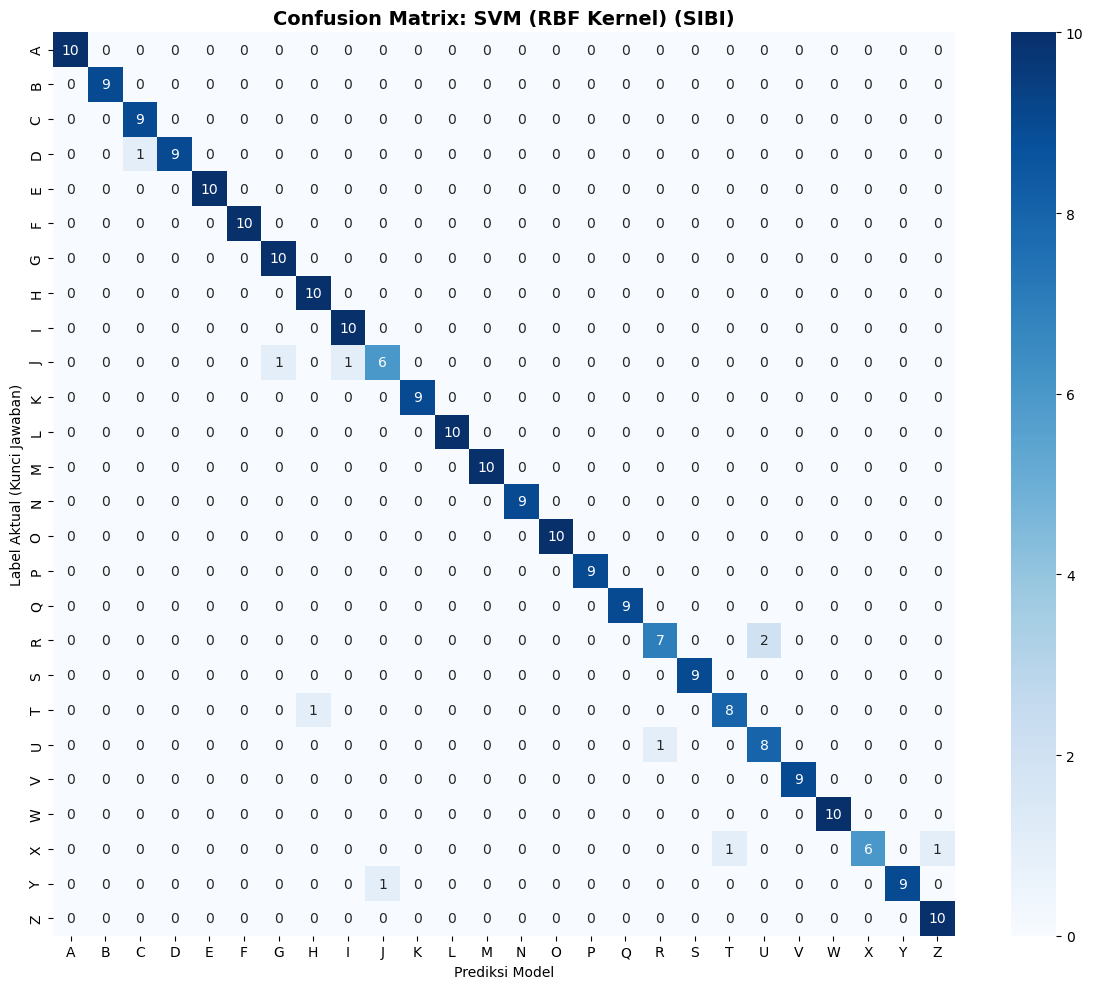

In [4]:
# Tentukan Model Terbaik berdasarkan F1-Score
best_model_name = df_results_sibi.sort_values(by="F1-Score", ascending=False).iloc[0]["Model / Algoritma"]
best_model = trained_models[best_model_name]
print(f"Model Terbaik Terpilih: {best_model_name}")

# Simpan model terbaik ke folder models/
joblib.dump(best_model, "models/best_model_sibi.joblib")
print("Model terbaik berhasil disimpan ke 'models/best_model_sibi.joblib'")

# Visualisasi Confusion Matrix Model Terbaik
y_pred_best = best_model.predict(X_test_sibi_scaled)
cm = confusion_matrix(y_test_sibi, y_pred_best)

plt.figure(figsize=(12, 10))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=le_sibi.classes_, 
            yticklabels=le_sibi.classes_)
plt.title(f"Confusion Matrix: {best_model_name} (SIBI)", fontsize=14, fontweight='bold')
plt.xlabel("Prediksi Model")
plt.ylabel("Label Aktual (Kunci Jawaban)")
plt.tight_layout()
plt.savefig("reports/figures/confusion_matrix_sibi.png", dpi=300)
plt.show()

C:\Users\hilma\AppData\Local\Temp\ipykernel_13084\4086969322.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_feat_imp, x='Importance', y='Fitur', palette='viridis')


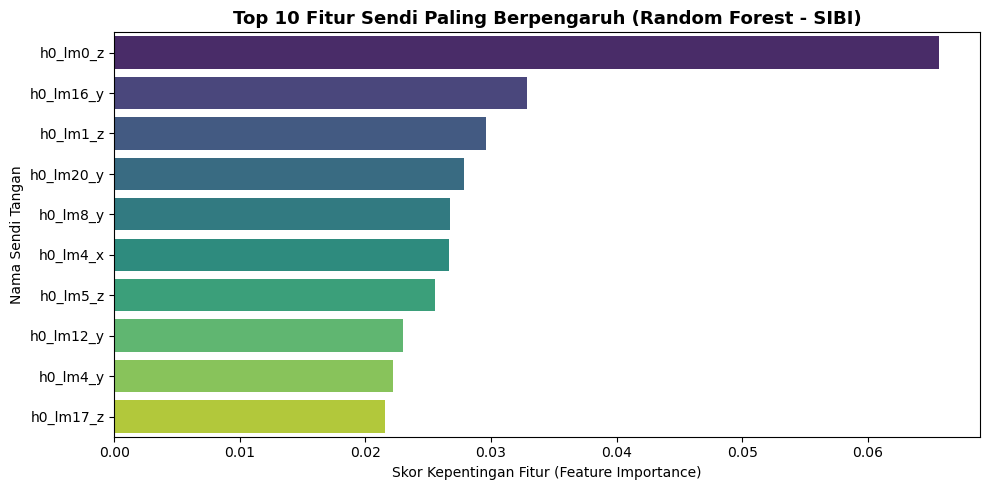

In [5]:
# Ekstrak 10 Fitur Sendi Paling Berpengaruh dari Random Forest
rf_model = trained_models["Random Forest"]
importances = rf_model.feature_importances_
feature_names = X_sibi.columns

df_feat_imp = pd.DataFrame({
    'Fitur': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False).head(10)

plt.figure(figsize=(10, 5))
sns.barplot(data=df_feat_imp, x='Importance', y='Fitur', palette='viridis')
plt.title("Top 10 Fitur Sendi Paling Berpengaruh (Random Forest - SIBI)", fontsize=13, fontweight='bold')
plt.xlabel("Skor Kepentingan Fitur (Feature Importance)")
plt.ylabel("Nama Sendi Tangan")
plt.tight_layout()
plt.savefig("reports/figures/feature_importance_sibi.png", dpi=300)
plt.show()

In [6]:
# ==============================================================
# PIPELINE PREPROCESSING & PEMODELAN BISINDO (DUAL HAND - 126 FITUR)
# ==============================================================

# 1. Pisahkan Fitur dan Label
X_bisindo = df_bisindo.drop(columns=['label'])
y_bisindo = df_bisindo['label']

le_bisindo = LabelEncoder()
y_bisindo_encoded = le_bisindo.fit_transform(y_bisindo)

# 2. Stratified Split 80:20
X_train_bis, X_test_bis, y_train_bis, y_test_bis = train_test_split(
    X_bisindo, y_bisindo_encoded, test_size=0.2, random_state=42, stratify=y_bisindo_encoded
)

# 3. Standard Scaler
scaler_bisindo = StandardScaler()
X_train_bis_scaled = scaler_bisindo.fit_transform(X_train_bis)
X_test_bis_scaled = scaler_bisindo.transform(X_test_bis)

# Simpan Scaler & LabelEncoder BISINDO
joblib.dump(scaler_bisindo, "models/scaler_bisindo.joblib")
joblib.dump(le_bisindo, "models/le_bisindo.joblib")

print(f"Data BISINDO siap latih:")
print(f"Train Shape: {X_train_bis_scaled.shape}, Test Shape: {X_test_bis_scaled.shape}\n")

# 4. Pelatihan 3 Algoritma pada BISINDO
models_bisindo = {
    "SVM (RBF Kernel)": SVC(kernel='rbf', C=10, gamma='scale', probability=True, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=15, random_state=42),
    "XGBoost": XGBClassifier(n_estimators=100, learning_rate=0.1, max_depth=6, random_state=42, eval_metric='mlogloss')
}

results_bisindo = []
trained_bisindo_models = {}

for name, model in models_bisindo.items():
    print(f"Sedang melatih: {name} (BISINDO)...")
    model.fit(X_train_bis_scaled, y_train_bis)
    
    y_pred = model.predict(X_test_bis_scaled)
    acc = accuracy_score(y_test_bis, y_pred)
    prec = precision_score(y_test_bis, y_pred, average='weighted', zero_division=0)
    rec = recall_score(y_test_bis, y_pred, average='weighted', zero_division=0)
    f1 = f1_score(y_test_bis, y_pred, average='weighted', zero_division=0)
    
    results_bisindo.append({
        "Model / Algoritma": name,
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1-Score": f1
    })
    trained_bisindo_models[name] = model

df_results_bisindo = pd.DataFrame(results_bisindo)
print("\n" + "="*65)
print("TABEL REKAPITULASI PERBANDINGAN MODEL (BISINDO)")
print("="*65)
display(df_results_bisindo)

# 5. Simpan Model BISINDO Terbaik
best_bisindo_name = df_results_bisindo.sort_values(by="F1-Score", ascending=False).iloc[0]["Model / Algoritma"]
best_bisindo_model = trained_bisindo_models[best_bisindo_name]
joblib.dump(best_bisindo_model, "models/best_model_bisindo.joblib")
print(f"\nModel Terbaik BISINDO: {best_bisindo_name} berhasil disimpan ke 'models/best_model_bisindo.joblib'!")

Data BISINDO siap latih:
Train Shape: (5135, 126), Test Shape: (1284, 126)

Sedang melatih: SVM (RBF Kernel) (BISINDO)...
Sedang melatih: Random Forest (BISINDO)...
Sedang melatih: XGBoost (BISINDO)...

TABEL REKAPITULASI PERBANDINGAN MODEL (BISINDO)


,Model / Algoritma,Accuracy,Precision,Recall,F1-Score
0,SVM (RBF Kernel),0.959502,0.960415,0.959502,0.959202
1,Random Forest,0.926791,0.928512,0.926791,0.926121
2,XGBoost,0.931464,0.933261,0.931464,0.931393



Model Terbaik BISINDO: SVM (RBF Kernel) berhasil disimpan ke 'models/best_model_bisindo.joblib'!
